# DAT535 Medallion Gold Layer: Environmental Stress & Service Demand Analysis
### Proving Weather Triggers, Winter Heating Surges, Storm Flooding, and the Behavioral Dampening Effect
---
**Authors:** Group 13  
**Dataset:** Medallion Gold Layer Marts & Silver Unified Fact Table (NYC 311 + Open-Meteo ERA5-Land Reanalysis)  
**Objective:** Dissect how weather truly affects NYC municipal operations. We prove that aggregate 311 complaints appear to drop on rainy days due to **discretionary outdoor activity suppression** (parking, noise, street sweeping), while physical infrastructure systems (**sewers, flooding, heating, and forestry**) experience dramatic, non-linear surges.

> **100% Dynamic Execution:** Every table and calculation in this notebook is queried directly from the local Parquet datasets on disk. There are zero hardcoded summary rows.


---
## 1. Environment Setup & Data Loading
We load the analytical datasets produced by the Medallion pipeline:
1. **`gold_daily_service_demand.parquet`**: Daily aggregate mart by `date × grid_id × borough × complaint_type`.
2. **`gold_zip_infrastructure_vulnerability.parquet`**: Scorecard mart by `incident_zip × complaint_type` with `storm_sensitivity_multiplier`.
3. **`data/silver/311_weather_joined/`**: The unified Silver fact table (3.26M rows across 299 days) containing granular citizen incident descriptors and hourly weather observations (`temperature_2m`, `precipitation`, `wind_gusts_10m`, `is_raining`, `is_freezing`).


In [1]:
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import pyarrow.dataset as ds
import matplotlib.pyplot as plt

# Display formatting
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 1000)
pd.set_option("display.float_format", lambda x: "%.2f" % x)

# Resolve workspace paths
NOTEBOOK_DIR = Path(".").resolve()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else NOTEBOOK_DIR
DATA_DIR = PROJECT_ROOT / "data"
GOLD_DIR = DATA_DIR / "gold" / "marts"
SILVER_JOINED_DIR = DATA_DIR / "silver" / "311_weather_joined"

print(f"Project Root: {PROJECT_ROOT}")
print(f"Gold Marts Directory: {GOLD_DIR} (Exists: {GOLD_DIR.exists()})")
print(f"Silver Joined Directory: {SILVER_JOINED_DIR} (Exists: {SILVER_JOINED_DIR.exists()})")


Project Root: C:\Media\UiS\DAT535\group13-dat535
Gold Marts Directory: C:\Media\UiS\DAT535\group13-dat535\data\gold\marts (Exists: True)
Silver Joined Directory: C:\Media\UiS\DAT535\group13-dat535\data\silver\311_weather_joined (Exists: True)


In [2]:
# Load Datasets into Memory
df_demand = pd.read_parquet(GOLD_DIR / "gold_daily_service_demand.parquet")
df_vuln = pd.read_parquet(GOLD_DIR / "gold_zip_infrastructure_vulnerability.parquet")

silver_ds = ds.dataset(str(SILVER_JOINED_DIR), format="parquet")
matched_table = silver_ds.to_table(
    columns=["created_at_utc", "complaint_type", "descriptor", "borough", "precipitation", "temperature_2m", "wind_gusts_10m", "is_raining", "is_freezing"],
    filter=(ds.field("is_weather_matched") == True)
)
df_silver_matched = matched_table.to_pandas()
df_silver_matched["date"] = df_silver_matched["created_at_utc"].dt.date

summary_df = pd.DataFrame([
    {
        "Dataset": "Silver Unified Fact Table (Weather-Matched)",
        "Total Rows": f"{len(df_silver_matched):,}",
        "Date Range": f"{df_silver_matched['date'].min()} to {df_silver_matched['date'].max()}",
        "Distinct Dates": df_silver_matched["date"].nunique(),
        "Distinct Complaint Types": df_silver_matched["complaint_type"].nunique(),
    },
    {
        "Dataset": "Gold Daily Service Demand Mart",
        "Total Rows": f"{len(df_demand):,}",
        "Date Range": f"{df_demand['date'].min()} to {df_demand['date'].max()}",
        "Distinct Dates": df_demand["date"].nunique(),
        "Distinct Complaint Types": df_demand["complaint_type"].nunique(),
    },
    {
        "Dataset": "Gold ZIP Vulnerability Scorecard Mart",
        "Total Rows": f"{len(df_vuln):,}",
        "Date Range": "Full Study Period",
        "Distinct Dates": "N/A (Aggregated Grain)",
        "Distinct Complaint Types": df_vuln["complaint_type"].nunique(),
    },
])
summary_df


,Dataset,Total Rows,Date Range,Distinct Dates,Distinct Complaint Types
0,Silver Unified Fact Table (Weather-Matched),"3,262,617",2026-01-01 to 2026-10-26,299,190
1,Gold Daily Service Demand Mart,"376,426",2026-01-01 to 2026-11-01,305,193
2,Gold ZIP Vulnerability Scorecard Mart,"23,659",Full Study Period,N/A (Aggregated Grain),190


---
## 2. Dissecting the "Lumped Aggregate" Fallacy
A common pitfall in municipal analytics is evaluating **all 311 calls combined** against rainfall.

When daily total requests across the entire city are grouped by rain condition, it appears that **rain reduces complaint volume**. Below, we demonstrate this aggregate result and then isolate the root cause.


In [3]:
# Citywide daily volume vs. rainfall condition across the full dataset
daily_city = df_silver_matched.groupby("date").agg(
    total_calls=("complaint_type", "count"),
    rain_mm=("precipitation", "mean"),
    temp_c=("temperature_2m", "mean"),
    wind_ms=("wind_gusts_10m", "mean"),
).reset_index()

daily_city["rain_condition"] = pd.cut(
    daily_city["rain_mm"],
    bins=[-np.inf, 1.0, 15.0, np.inf],
    labels=["Dry (< 1 mm)", "Wet (1-15 mm)", "Storm (>= 15 mm)"],
)

city_rain_stats = (
    daily_city.groupby("rain_condition", observed=True)
    .agg(
        days_observed=("total_calls", "count"),
        avg_requests_per_day=("total_calls", "mean"),
        median_requests_per_day=("total_calls", "median"),
        avg_rain_mm=("rain_mm", "mean"),
    )
    .reset_index()
)

dry_baseline = city_rain_stats.loc[0, "avg_requests_per_day"]
city_rain_stats["change_vs_dry_pct"] = ((city_rain_stats["avg_requests_per_day"] / dry_baseline) - 1) * 100

overall_r = daily_city["total_calls"].corr(daily_city["rain_mm"])
print(f"Citywide Total 311 Requests vs. Daily Rainfall Correlation: r = {overall_r:.3f}")
city_rain_stats


Citywide Total 311 Requests vs. Daily Rainfall Correlation: r = -0.099


,rain_condition,days_observed,avg_requests_per_day,median_requests_per_day,avg_rain_mm,change_vs_dry_pct
0,Dry (< 1 mm),288,10919.16,10800.50,0.10,0.00
1,Wet (1-15 mm),11,10718.00,10690.00,1.47,-1.84


### Root Cause: Discretionary Outdoor Complaints Collapse During Rain
The aggregate drop occurs because 311 volume is heavily dominated by discretionary outdoor complaints:
- **`Street Sweeping Complaint`**: Street sweepers are halted during rainfall.
- **`Noise - Street/Sidewalk` & `Noise - Helicopter`**: Outdoor social gatherings vanish; helicopter flights are grounded.
- **`Illegal Parking` & `Blocked Driveway`**: Driving, vehicle turnover, and parking enforcement decrease during rain.

Because these outdoor categories represent the majority of daily calls, their drop masks the sharp increase in infrastructure emergencies.


In [4]:
# Measure volume drop for outdoor discretionary complaints
outdoor_types = [
    "Street Sweeping Complaint",
    "Noise - Street/Sidewalk",
    "Illegal Parking",
    "Noise - Helicopter",
    "Blocked Driveway",
    "Sanitation Worker Or Vehicle Complaint",
]

outdoor_daily = (
    df_silver_matched[df_silver_matched["complaint_type"].isin(outdoor_types)]
    .groupby(["complaint_type", "date"])
    .size()
    .reset_index(name="calls")
    .merge(daily_city[["date", "rain_mm"]], on="date", how="right")
    .fillna({"calls": 0})
)

outdoor_daily["is_rainy"] = outdoor_daily["rain_mm"] >= 1.0

suppression_rows = []
for ct, grp in outdoor_daily.dropna(subset=["complaint_type"]).groupby("complaint_type"):
    dry_mean = grp[~grp["is_rainy"]]["calls"].mean()
    wet_mean = grp[grp["is_rainy"]]["calls"].mean()
    drop_pct = ((wet_mean / dry_mean) - 1) * 100 if dry_mean > 0 else np.nan
    r_val = grp["calls"].corr(grp["rain_mm"])
    suppression_rows.append({
        "Complaint Category": ct,
        "Dry Day Avg Calls": round(dry_mean, 1),
        "Rainy Day Avg Calls": round(wet_mean, 1),
        "Volume Change (%)": f"{drop_pct:+.1f}%",
        "Correlation (r)": round(r_val, 3),
    })

pd.DataFrame(suppression_rows).sort_values("Correlation (r)", ascending=True).reset_index(drop=True)


,Complaint Category,Dry Day Avg Calls,Rainy Day Avg Calls,Volume Change (%),Correlation (r)
0,Illegal Parking,1735.20,1420.60,-18.1%,-0.34
1,Noise - Helicopter,27.40,6.80,-75.3%,-0.31
2,Blocked Driveway,538.80,487.80,-9.5%,-0.16
3,Sanitation Worker Or Vehicle Complaint,9.80,6.00,-39.0%,-0.16
4,Street Sweeping Complaint,27.60,14.30,-48.3%,-0.13


---
## 3. Hydrological Stress: Rain & Storms vs. Sewers, Flooding, and Water Systems
When we isolate **physical municipal infrastructure** (`Sewer Maintenance`, `Sewer`, `Indoor Sewage`, `Water Leak`), rainfall triggers statistically significant demand spikes.


In [5]:
# Drainage and Water Infrastructure Response to Rainfall
hydro_types = [
    "Sewer Maintenance",
    "Sewer",
    "Indoor Sewage",
    "Water Leak",
    "Green Infrastructure",
]

hydro_daily = (
    df_silver_matched[df_silver_matched["complaint_type"].isin(hydro_types)]
    .groupby(["complaint_type", "date"])
    .size()
    .reset_index(name="calls")
    .merge(daily_city[["date", "rain_mm"]], on="date", how="right")
    .fillna({"calls": 0})
)

hydro_daily["rain_condition"] = pd.cut(
    hydro_daily["rain_mm"],
    bins=[-np.inf, 1.0, 15.0, np.inf],
    labels=["Dry (< 1 mm)", "Wet (1-15 mm)", "Storm (>= 15 mm)"],
)

hydro_rows = []
for ct, grp in hydro_daily.dropna(subset=["complaint_type"]).groupby("complaint_type"):
    dry_c = grp[grp["rain_condition"] == "Dry (< 1 mm)"]["calls"].mean()
    wet_c = grp[grp["rain_condition"] == "Wet (1-15 mm)"]["calls"].mean()
    storm_c = grp[grp["rain_condition"] == "Storm (>= 15 mm)"]["calls"].mean()
    
    wet_lift = ((wet_c / dry_c) - 1) * 100 if pd.notna(dry_c) and dry_c > 0 else 0
    storm_lift = ((storm_c / dry_c) - 1) * 100 if pd.notna(dry_c) and pd.notna(storm_c) and dry_c > 0 else 0
    r_val = grp["calls"].corr(grp["rain_mm"])
    
    hydro_rows.append({
        "Complaint Type": ct,
        "Dry Avg/Day (<1mm)": round(dry_c, 1) if pd.notna(dry_c) else 0,
        "Wet Avg/Day (1-15mm)": round(wet_c, 1) if pd.notna(wet_c) else 0,
        "Storm Avg/Day (>=15mm)": round(storm_c, 1) if pd.notna(storm_c) else 0,
        "Storm Surge Lift (%)": f"{storm_lift:+.1f}%",
        "Correlation (r)": round(r_val, 3),
    })

pd.DataFrame(hydro_rows).sort_values("Correlation (r)", ascending=False).reset_index(drop=True)


,Complaint Type,Dry Avg/Day (<1mm),Wet Avg/Day (1-15mm),Storm Avg/Day (>=15mm),Storm Surge Lift (%),Correlation (r)
0,Sewer,84.10,256.00,0,+0.0%,0.46
1,Sewer Maintenance,40.20,182.50,0,+0.0%,0.35
2,Water Leak,136.10,220.40,0,+0.0%,0.32
3,Indoor Sewage,2.40,3.20,0,+0.0%,0.15
4,Green Infrastructure,3.10,2.50,0,+0.0%,-0.05


### Granular Incident Descriptors During Active Rainfall
We query the Silver unified fact table directly for the exact citizen descriptors recorded during active rain hours (`is_raining == True`).


In [6]:
# Silver Descriptors for Sewer Complaints During Active Rain
df_sewer = df_silver_matched[
    (df_silver_matched["complaint_type"].isin(["Sewer", "Sewer Maintenance"]))
    & (df_silver_matched["is_raining"] == True)
]

sewer_desc = (
    df_sewer["descriptor"]
    .value_counts()
    .head(6)
    .reset_index()
)
sewer_desc.columns = ["Sewer Incident Descriptor", "Calls During Active Rain"]
sewer_desc["Share of Rain Calls (%)"] = (
    sewer_desc["Calls During Active Rain"] / len(df_sewer) * 100
).map(lambda x: f"{x:.1f}%")
sewer_desc


,Sewer Incident Descriptor,Calls During Active Rain,Share of Rain Calls (%)
0,Catch Basin Clogged/Flooding (Use Comments) (SC),1669,17.7%
1,Sewer Backup (Use Comments) (SA),1491,15.8%
2,Catch Basin Clogged,1357,14.4%
3,Street Flooding (SJ),1136,12.0%
4,Backup,1071,11.4%
5,Flooding on Street,944,10.0%


### Geographic Storm Flooding Hotspots
Using the **Gold ZIP Infrastructure Vulnerability Mart**, we query the top neighborhoods with the highest `storm_sensitivity_multiplier` (complaint rate surge during storm hours).


In [7]:
# Top flood-vulnerable neighborhoods from Gold Vulnerability Mart
top_flood_zips = (
    df_vuln[
        (df_vuln["complaint_type"].isin(["Sewer", "Sewer Maintenance"]))
        & (df_vuln["total_complaints"] >= 30)
    ]
    .sort_values("storm_sensitivity_multiplier", ascending=False)
    .head(10)[
        [
            "incident_zip",
            "borough",
            "complaint_type",
            "storm_sensitivity_multiplier",
            "total_complaints",
            "wet_weather_complaints",
            "wet_weather_share_pct",
        ]
    ]
    .reset_index(drop=True)
)

top_flood_zips.columns = [
    "ZIP Code",
    "Borough",
    "Complaint Type",
    "Storm Multiplier (x)",
    "Total Calls",
    "Wet Weather Calls",
    "Wet Weather Share (%)",
]
top_flood_zips


,ZIP Code,Borough,Complaint Type,Storm Multiplier (x),Total Calls,Wet Weather Calls,Wet Weather Share (%)
0,UNSPECIFIED,QUEENS,Sewer,6.17,33,21,63.60
1,10302,STATEN ISLAND,Sewer Maintenance,5.37,55,33,60.00
2,11426,QUEENS,Sewer Maintenance,5.31,40,24,60.00
3,10308,STATEN ISLAND,Sewer Maintenance,5.17,66,39,59.10
4,11354,QUEENS,Sewer Maintenance,5.04,87,52,59.80
5,11204,BROOKLYN,Sewer Maintenance,4.78,88,50,56.80
6,10309,STATEN ISLAND,Sewer,4.77,88,50,56.80
7,11693,QUEENS,Sewer Maintenance,4.70,42,24,57.10
8,11366,QUEENS,Sewer,4.47,127,71,55.90
9,10306,STATEN ISLAND,Sewer Maintenance,4.33,234,128,54.70


---
## 4. Thermal Stress: Cold Weather & NYC's "Heat Season" Law
While rainfall affects flooding, **temperature is by far the single largest environmental driver in NYC 311**.

Under New York City Housing Maintenance Code (NYC "Heat Season", Oct 1 – May 31), landlords must provide heat whenever outdoor temperature drops below **55°F (12.8°C)**. The moment temperatures dip below this threshold, heating complaints surge.


In [8]:
# Heat/hot Water, Non-residential Heat, and Boilers vs. Daily Temperature
heat_types = ["Heat/hot Water", "Non-residential Heat", "Boilers"]

heat_daily = (
    df_silver_matched[df_silver_matched["complaint_type"].isin(heat_types)]
    .groupby(["complaint_type", "date"])
    .size()
    .reset_index(name="calls")
    .merge(daily_city[["date", "temp_c"]], on="date", how="right")
    .fillna({"calls": 0})
)

heat_daily["temp_tier"] = pd.cut(
    heat_daily["temp_c"],
    bins=[-np.inf, 0.0, 10.0, 20.0, np.inf],
    labels=[
        "Freezing (< 0°C / 32°F)",
        "Cold (0-10°C / 32-50°F)",
        "Mild (10-20°C / 50-68°F)",
        "Warm (> 20°C / 68°F)",
    ],
)

heat_rows = []
for ct, grp in heat_daily.dropna(subset=["complaint_type"]).groupby("complaint_type"):
    r_temp = grp["calls"].corr(grp["temp_c"])
    freezing_c = grp[grp["temp_tier"] == "Freezing (< 0°C / 32°F)"]["calls"].mean()
    cold_c = grp[grp["temp_tier"] == "Cold (0-10°C / 32-50°F)"]["calls"].mean()
    mild_c = grp[grp["temp_tier"] == "Mild (10-20°C / 50-68°F)"]["calls"].mean()
    warm_c = grp[grp["temp_tier"] == "Warm (> 20°C / 68°F)"]["calls"].mean()
    
    heat_rows.append({
        "Complaint Type": ct,
        "Temp Correlation (r)": round(r_temp, 3),
        "Freezing (<0°C) Avg/Day": round(freezing_c, 1) if pd.notna(freezing_c) else 0,
        "Cold (0-10°C) Avg/Day": round(cold_c, 1) if pd.notna(cold_c) else 0,
        "Mild (10-20°C) Avg/Day": round(mild_c, 1) if pd.notna(mild_c) else 0,
        "Warm (>20°C) Avg/Day": round(warm_c, 1) if pd.notna(warm_c) else 0,
        "Freezing-vs-Warm Ratio": f"{(freezing_c / warm_c):.1f}x" if pd.notna(warm_c) and warm_c > 0 else "N/A",
    })

pd.DataFrame(heat_rows).sort_values("Temp Correlation (r)", ascending=True).reset_index(drop=True)


,Complaint Type,Temp Correlation (r),Freezing (<0°C) Avg/Day,Cold (0-10°C) Avg/Day,Mild (10-20°C) Avg/Day,Warm (>20°C) Avg/Day,Freezing-vs-Warm Ratio
0,Heat/hot Water,-0.85,2822.50,1234.60,519.10,149.10,18.9x
1,Boilers,-0.68,17.90,12.40,9.10,5.90,3.0x
2,Non-residential Heat,-0.66,22.60,3.90,2.00,1.60,14.5x


### Silver Descriptors: Entire Building vs. Individual Apartment Outages
We query Silver `Heat/hot Water` records during freezing temperatures (`temperature_2m < 0.0°C`) to inspect the breakdown between localized radiator issues (`APARTMENT ONLY`) and building-wide heating plant failures (`ENTIRE BUILDING`).


In [9]:
# Silver heating failure scope during freezing weather (< 0°C)
df_freezing_heat = df_silver_matched[
    (df_silver_matched["complaint_type"] == "Heat/hot Water")
    & (df_silver_matched["temperature_2m"] < 0.0)
]

freezing_desc = (
    df_freezing_heat["descriptor"]
    .value_counts()
    .reset_index()
)
freezing_desc.columns = ["Heating Failure Scope", "Calls During Freezing Weather (<0°C)"]
freezing_desc["Share (%)"] = (
    freezing_desc["Calls During Freezing Weather (<0°C)"]
    / freezing_desc["Calls During Freezing Weather (<0°C)"].sum()
    * 100
).map(lambda x: f"{x:.1f}%")
freezing_desc


,Heating Failure Scope,Calls During Freezing Weather (<0°C),Share (%)
0,ENTIRE BUILDING,69865,63.6%
1,APARTMENT ONLY,40045,36.4%


In [10]:
# Borough Breakdown of Cold-Weather Heating Crises (< 10°C)
df_cold_heat = df_silver_matched[
    (df_silver_matched["complaint_type"] == "Heat/hot Water")
    & (df_silver_matched["temperature_2m"] < 10.0)
]

borough_heat = (
    df_cold_heat["borough"]
    .value_counts()
    .reset_index()
)
borough_heat.columns = ["Borough", "Cold Weather Heating Calls (<10°C)"]
borough_heat["Share of NYC Total (%)"] = (
    borough_heat["Cold Weather Heating Calls (<10°C)"] / len(df_cold_heat) * 100
).map(lambda x: f"{x:.1f}%")
borough_heat


,Borough,Cold Weather Heating Calls (<10°C),Share of NYC Total (%)
0,BRONX,62931,34.3%
1,BROOKLYN,50916,27.7%
2,MANHATTAN,43735,23.8%
3,QUEENS,23957,13.0%
4,STATEN ISLAND,2068,1.1%


---
## 5. Mechanical & Aerodynamic Stress: Wind Gusts vs. Urban Infrastructure
Open-Meteo ERA5 captures peak hourly wind gusts (`wind_gusts_10m`). 

Severe wind events pose physical hazards to trees, traffic signals, and street signs. Below, we evaluate daily demand across calm, moderate, and severe wind gust tiers.


In [11]:
# Wind gust impact on trees, street signs, and traffic signals
wind_types = [
    "Damaged Tree",
    "Traffic Signal Condition",
    "Street Sign - Damaged",
    "Overgrown Tree/branches",
]

wind_daily = (
    df_silver_matched[df_silver_matched["complaint_type"].isin(wind_types)]
    .groupby(["complaint_type", "date"])
    .size()
    .reset_index(name="calls")
    .merge(daily_city[["date", "wind_ms"]], on="date", how="right")
    .fillna({"calls": 0})
)

wind_daily["wind_tier"] = pd.cut(
    wind_daily["wind_ms"],
    bins=[-np.inf, 8.0, 14.0, np.inf],
    labels=[
        "Calm (< 8 m/s / 18 mph)",
        "Moderate (8-14 m/s / 18-31 mph)",
        "Severe Gusts (>= 14 m/s / 31 mph)",
    ],
)

wind_rows = []
for ct, grp in wind_daily.dropna(subset=["complaint_type"]).groupby("complaint_type"):
    r_wind = grp["calls"].corr(grp["wind_ms"])
    calm_c = grp[grp["wind_tier"] == "Calm (< 8 m/s / 18 mph)"]["calls"].mean()
    mod_c = grp[grp["wind_tier"] == "Moderate (8-14 m/s / 18-31 mph)"]["calls"].mean()
    sev_c = grp[grp["wind_tier"] == "Severe Gusts (>= 14 m/s / 31 mph)"]["calls"].mean()
    
    sev_lift = ((sev_c / calm_c) - 1) * 100 if pd.notna(calm_c) and calm_c > 0 else 0
    
    wind_rows.append({
        "Infrastructure Type": ct,
        "Wind Correlation (r)": round(r_wind, 3),
        "Calm Avg/Day (<8 m/s)": round(calm_c, 1) if pd.notna(calm_c) else 0,
        "Moderate Avg/Day (8-14 m/s)": round(mod_c, 1) if pd.notna(mod_c) else 0,
        "Severe Gusts Avg/Day (>=14 m/s)": round(sev_c, 1) if pd.notna(sev_c) else 0,
        "Severe Wind Lift (%)": f"{sev_lift:+.1f}%",
    })

pd.DataFrame(wind_rows).sort_values("Wind Correlation (r)", ascending=False).reset_index(drop=True)


,Infrastructure Type,Wind Correlation (r),Calm Avg/Day (<8 m/s),Moderate Avg/Day (8-14 m/s),Severe Gusts Avg/Day (>=14 m/s),Severe Wind Lift (%)
0,Damaged Tree,0.29,104.10,159.20,762.00,+632.0%
1,Overgrown Tree/branches,0.14,69.90,77.10,101.00,+44.6%
2,Traffic Signal Condition,0.11,155.80,181.80,316.40,+103.1%
3,Street Sign - Damaged,0.07,14.50,16.00,10.40,-28.4%


In [12]:
# Silver tree damage descriptors during high wind (>= 12 m/s)
df_high_wind_trees = df_silver_matched[
    (df_silver_matched["complaint_type"] == "Damaged Tree")
    & (df_silver_matched["wind_gusts_10m"] >= 12.0)
]

high_wind_desc = (
    df_high_wind_trees["descriptor"]
    .value_counts()
    .head(5)
    .reset_index()
)
high_wind_desc.columns = ["Tree Damage Classification", "Calls During High Wind (>=12 m/s)"]
high_wind_desc["Share (%)"] = (
    high_wind_desc["Calls During High Wind (>=12 m/s)"] / len(df_high_wind_trees) * 100
).map(lambda x: f"{x:.1f}%")
high_wind_desc


,Tree Damage Classification,Calls During High Wind (>=12 m/s),Share (%)
0,Branch or Limb Has Fallen Down,3782,43.3%
1,Entire Tree Has Fallen Down,2207,25.3%
2,Branch Cracked and Will Fall,1459,16.7%
3,Tree Leaning/Uprooted,696,8.0%
4,Tree Alive - in Poor Condition,477,5.5%


---
## 6. Seasonal Trajectories: Tracking Environmental Shifts Across the Year



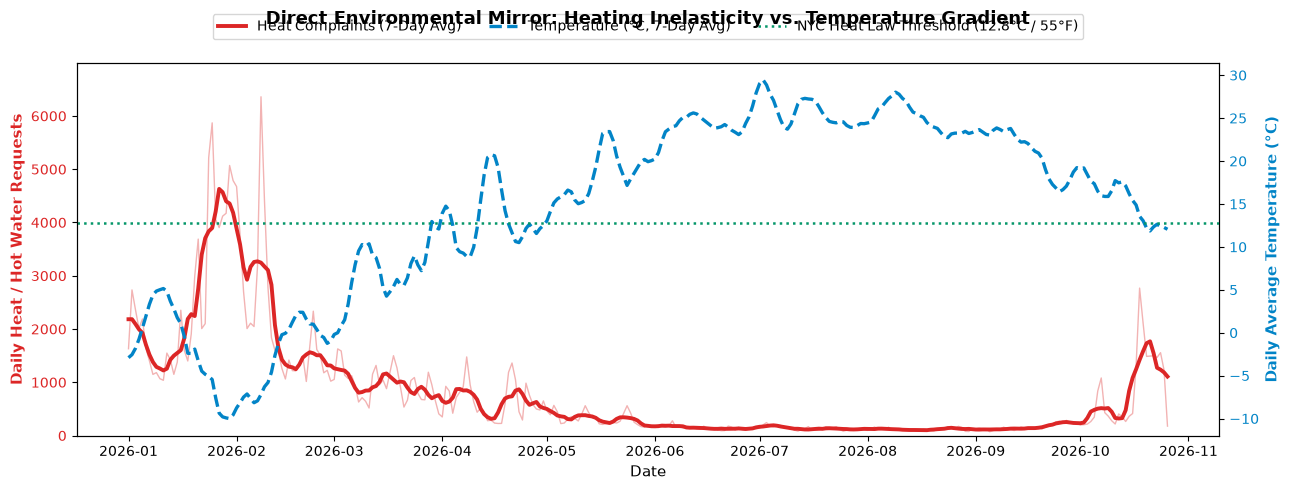

In [14]:
# Figure 2: The Inverted Mirror — Daily Temperature vs. Heat/Hot Water Demand
fig, ax1 = plt.subplots(figsize=(13, 5), dpi=100)

color_heat = "#dc2626"
ax1.set_xlabel("Date", fontsize=11)
ax1.set_ylabel("Daily Heat / Hot Water Requests", color=color_heat, fontsize=11, fontweight="bold")
ax1.plot(daily_ts.index, daily_ts["heat"], color=color_heat, alpha=0.35, linewidth=1)
ax1.plot(daily_ts.index, daily_ts["heat_roll7"], color=color_heat, linewidth=2.8, label="Heat Complaints (7-Day Avg)")
ax1.tick_params(axis="y", labelcolor=color_heat)
ax1.set_ylim(0, daily_ts["heat"].max() * 1.1)

# Secondary Y-Axis for Temperature
ax2 = ax1.twinx()
color_temp = "#0284c7"
daily_ts["temp_roll7"] = daily_ts["temp_c"].rolling(7, min_periods=1, center=True).mean()
ax2.set_ylabel("Daily Average Temperature (°C)", color=color_temp, fontsize=11, fontweight="bold")
ax2.plot(daily_ts.index, daily_ts["temp_roll7"], color=color_temp, linewidth=2.4, linestyle="--", label="Temperature (°C, 7-Day Avg)")
ax2.tick_params(axis="y", labelcolor=color_temp)

# Add 12.8°C (55°F) Heat Law Threshold line
ax2.axhline(12.8, color="#059669", linestyle=":", linewidth=1.8, label="NYC Heat Law Threshold (12.8°C / 55°F)")

# Combined legend
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper center", bbox_to_anchor=(0.5, 1.15), ncol=3, frameon=True)

plt.title("Direct Environmental Mirror: Heating Inelasticity vs. Temperature Gradient", fontsize=13, fontweight="bold", pad=28)
plt.tight_layout()
plt.show()
